**2. Assignment: RNA-Seq Data Analysis. Task: Analyze a provided RNA-Seq dataset and perform differential
gene expression analysis. Deliverable: A detailed report presenting the differentially expressed genes, their
functional annotations, and any potential biological interpretations**

In [1]:
!pip install pandas numpy scipy matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind

In [ ]:
#creating sample RNA-seq dataset
data = {
    "Gene": ["TP53", "BRCA1", "INS", "EGFR", "MYC", "ACTB"],
    "Function": [
        "Tumor suppression",
        "DNA repair",
        "Insulin production",
        "Cell growth",
        "Cell proliferation",
        "Cell structure"
    ],
    "Control_1": [100, 200, 50, 100, 150, 300],
    "Control_2": [110, 190, 55, 105, 145, 310],
    "Control_3": [95, 210, 48, 95, 155, 290],
    "Treatment_1": [300, 50, 200, 400, 40, 310],
    "Treatment_2": [320, 55, 210, 420, 45, 305],
    "Treatment_3": [290, 48, 190, 390, 35, 295]
}

df = pd.DataFrame(data)

print(df)
#Our dataset contains:
# - Gene: Gene name.
# - Function: Biological function.
# - Control_1, Control_2, Control_3: Control group expression counts.
# - Treatment_1, Treatment_2, Treatment_3: Treatment group expression counts.

    Gene            Function  Control_1  Control_2  Control_3  Treatment_1  \
0   TP53   Tumor suppression        100        110         95          300   
1  BRCA1          DNA repair        200        190        210           50   
2    INS  Insulin production         50         55         48          200   
3   EGFR         Cell growth        100        105         95          400   
4    MYC  Cell proliferation        150        145        155           40   
5   ACTB      Cell structure        300        310        290          310   

   Treatment_2  Treatment_3  
0          320          290  
1           55           48  
2          210          190  
3          420          390  
4           45           35  
5          305          295  


In [4]:
#explore the dataset
print("Dataset Shape:", df.shape)

print("\nFirst Five Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (6, 8)

First Five Records:
    Gene            Function  Control_1  Control_2  Control_3  Treatment_1  \
0   TP53   Tumor suppression        100        110         95          300   
1  BRCA1          DNA repair        200        190        210           50   
2    INS  Insulin production         50         55         48          200   
3   EGFR         Cell growth        100        105         95          400   
4    MYC  Cell proliferation        150        145        155           40   

   Treatment_2  Treatment_3  
0          320          290  
1           55           48  
2          210          190  
3          420          390  
4           45           35  

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Gene         6 non-null      str  
 1   Function     6 non-null      str  
 2   Control_1    6 non-null      int

In [ ]:
#calculate average gene expression
control = ["Control_1", "Control_2", "Control_3"]
treatment = ["Treatment_1", "Treatment_2", "Treatment_3"]

df["Control_Mean"] = df[control].mean(axis=1)

df["Treatment_Mean"] = df[treatment].mean(axis=1)

print(df[["Gene", "Control_Mean", "Treatment_Mean"]])

# mean(axis=1) calculates the average across sample columns for each gene.
# We calculate separate averages for control and treatment groups.
# This helps us compare gene expression.

    Gene  Control_Mean  Treatment_Mean
0   TP53    101.666667      303.333333
1  BRCA1    200.000000       51.000000
2    INS     51.000000      200.000000
3   EGFR    100.000000      403.333333
4    MYC    150.000000       40.000000
5   ACTB    300.000000      303.333333


In [6]:
#calculate log2 Fold change
#Fold change measures how much gene expression increases or decreases between the two groups.
df["log2FC"] = np.log2(
    (df["Treatment_Mean"] + 1) /
    (df["Control_Mean"] + 1)
)

print(df[["Gene", "log2FC"]])

# Positive log2FC means upregulation.
# Negative log2FC means downregulation.
# Zero means approximately equal expression

    Gene    log2FC
0   TP53  1.567685
1  BRCA1 -1.950612
2    INS  1.950612
3   EGFR  2.001190
4    MYC -1.880853
5   ACTB  0.015889


In [7]:
#performing differential gene expression analysis
p_values = []

for i, row in df.iterrows():

    control_values = row[control].values.astype(float)
    treatment_values = row[treatment].values.astype(float)

    p = ttest_ind(
        treatment_values,
        control_values,
        equal_var=False
    ).pvalue

    p_values.append(p)

df["p_value"] = p_values
print(df[["Gene", "log2FC", "p_value"]])

# ttest_ind() compares the expression levels between two independent groups.
# It calculates a p-value for each gene.
# A smaller p-value indicates stronger evidence of a difference in expression.

    Gene    log2FC   p_value
0   TP53  1.567685  0.000290
1  BRCA1 -1.950612  0.000480
2    INS  1.950612  0.000480
3   EGFR  2.001190  0.000289
4    MYC -1.880853  0.000011
5   ACTB  0.015889  0.671737


In [ ]:
#Benjamini-Hochberg (BH) method.
!pip install statsmodels
from statsmodels.stats.multitest import multipletests

df["Adjusted_p"] = multipletests(
    df["p_value"],
    method="fdr_bh"
)[1]

print(df[["Gene", "p_value", "Adjusted_p"]])

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------------- -------------------------- 3.9/11.3 MB 19.5 MB/s eta 0:00:01
   --------------------------- ------------ 7.9/11.3 MB 18.9 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.3 MB 18.5 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 17.0 MB/s  0:00:00

   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ---------------- ----------------------- 2/5 [interface-meta]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   --------

In [10]:
#identify upregulated and downregulated genes
def classify(row):

    if row["Adjusted_p"] < 0.05 and row["log2FC"] >= 1:
        return "Upregulated"

    elif row["Adjusted_p"] < 0.05 and row["log2FC"] <= -1:
        return "Downregulated"

    else:
        return "Not Significant"


df["Regulation"] = df.apply(classify, axis=1)

print(df[["Gene", "log2FC", "Adjusted_p", "Regulation"]])

    Gene    log2FC  Adjusted_p       Regulation
0   TP53  1.567685    0.000576      Upregulated
1  BRCA1 -1.950612    0.000576    Downregulated
2    INS  1.950612    0.000576      Upregulated
3   EGFR  2.001190    0.000576      Upregulated
4    MYC -1.880853    0.000068    Downregulated
5   ACTB  0.015889    0.671737  Not Significant


In [11]:
#functional annotation
significant = df[df["Regulation"] != "Not Significant"]

print("Functional Annotation:")

print(significant[[
    "Gene",
    "Function",
    "Regulation"
]])

Functional Annotation:
    Gene            Function     Regulation
0   TP53   Tumor suppression    Upregulated
1  BRCA1          DNA repair  Downregulated
2    INS  Insulin production    Upregulated
3   EGFR         Cell growth    Upregulated
4    MYC  Cell proliferation  Downregulated


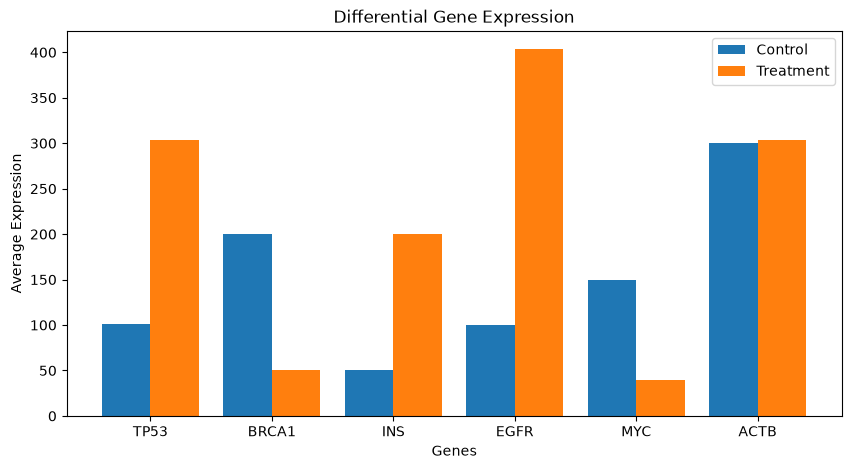

In [12]:
#visualize gene expression
plt.figure(figsize=(10, 5))

x = np.arange(len(df))

plt.bar(x - 0.2, df["Control_Mean"], 
        width=0.4, label="Control")

plt.bar(x + 0.2, df["Treatment_Mean"], 
        width=0.4, label="Treatment")

plt.xticks(x, df["Gene"])

plt.xlabel("Genes")
plt.ylabel("Average Expression")

plt.title("Differential Gene Expression")

plt.legend()
plt.show()

In [13]:
print("========== RNA-SEQ ANALYSIS REPORT ==========")

print("\nTotal Genes:", len(df))

print("Upregulated Genes:",
      len(df[df["Regulation"] == "Upregulated"]))

print("Downregulated Genes:",
      len(df[df["Regulation"] == "Downregulated"]))

print("\nDifferentially Expressed Genes:")

print(significant[[
    "Gene", "Function", "log2FC",
    "Adjusted_p", "Regulation"
]])

print("\n========== ANALYSIS COMPLETED ==========")

========== RNA-SEQ ANALYSIS REPORT ==========

Total Genes: 6
Upregulated Genes: 3
Downregulated Genes: 2

Differentially Expressed Genes:
    Gene            Function    log2FC  Adjusted_p     Regulation
0   TP53   Tumor suppression  1.567685    0.000576    Upregulated
1  BRCA1          DNA repair -1.950612    0.000576  Downregulated
2    INS  Insulin production  1.950612    0.000576    Upregulated
3   EGFR         Cell growth  2.001190    0.000576    Upregulated
4    MYC  Cell proliferation -1.880853    0.000068  Downregulated

========== ANALYSIS COMPLETED ==========
